In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.metrics import (
silhouette_score,
davies_bouldin_score,
calinski_harabasz_score
)

# Предобработка данных

In [2]:
df = pd.read_csv('../digit.dat', sep=';')
df = (df.apply(lambda col: col.str.strip())
      .loc[:, "A":"H"] 
      .replace({"ZERO": 0, "ONE": 1, "zero": 0,
             "one": 1, "two": 2, "three": 3,
             "four": 4, "five": 5, "six": 6,
             "seven": 7, "eight": 8, "nine": 9})
      .astype(int))

df.head()

,A,B,C,D,E,F,G,H
0,7,1,0,1,0,0,1,0
1,1,0,0,1,0,0,1,0
2,4,0,1,1,1,0,1,0
3,2,1,1,1,1,1,0,0
4,8,0,1,1,1,1,1,1


# Кластеризация методом DBSCAN

In [3]:
# Применим стили для графиков
plt.style.use('seaborn-v0_8')
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.grid": True,
})

In [4]:
X = df.loc[:, "B":"H"]
y = df["A"]

### Выбор метрики расстояния
Для бинарных векторов фиксированной длины евклидово расстояние и расстояние Хэмминга связаны соотношением:
$$
d_E(A,B) = \sqrt{7d_H(A,B)}
$$
Таким образом, обе метрики одинаково упорядочивают расстояния между объектами. При соответствующем расчете $\varepsilon$ DBSCAN формирует одинаковые окрестности и, следовательно, одинаковые кластеры. Поэтому выбор между этими метриками в данной задаче не принципиален. Остановимся на расстоянии Хэмминга

### Задание сетки параметров  
Данные представлены бинарными векторами из 7 сегментов, поэтому расстояние Хэмминга может принимать только значения 0, 1/7, 2/7, ..., 1. Исходя из этого значения $\varepsilon$ следует выбрать вблизи этих порогов с небольшим положительным смещением, чтобы гарантировать включение точек на границе окрестности. Перебор промежуточных значений не имеет смысла, поскольку состав окрестностей не изменяется.

In [5]:
eps_values = np.array([0, 1, 2]) / 7 + 1e-6
n_values = [2, 3, 5, 10, 15, 20, 30]

Проведем кластеризацию для каждой пары значений и посмотрим на:
- Количество кластеров
- Количество выбросов (шума)
- Минимальный размер кластера
- Максимальный размер кластера
- Метрики: силуэт, индекс Дэвиса-Болдина, индекс Калински-Харабаша

In [6]:
results = []
for eps in eps_values:
    for n in n_values:

        model = DBSCAN(
            eps=eps,
            min_samples=n,
            metric='hamming'
        )

        labels = model.fit_predict(X)

        mask = labels != -1
        labels_clusters = labels[mask]
        X_clusters = X[mask]

        _, counts = np.unique(labels_clusters, return_counts=True)

        n_clusters = len(counts)
        n_noise = np.sum(~mask)

        silhouette = np.nan
        davies_bouldin = np.nan
        calinski_harabasz = np.nan

        if 2 <= n_clusters < len(X_clusters):
            silhouette = silhouette_score(X_clusters, labels_clusters, metric='hamming')
            davies_bouldin = davies_bouldin_score(X_clusters, labels_clusters)
            calinski_harabasz = calinski_harabasz_score(X_clusters, labels_clusters)

        results.append({
            'epsilon': round(eps, 4),
            'n': n,
            'n_clusters': n_clusters,
            'n_noise': n_noise,
            'min_cluster_size': counts.min() if n_clusters else np.nan,
            'max_cluster_size': counts.max() if n_clusters else np.nan,
            'silhouette': silhouette,
            'davies_bouldin': davies_bouldin,
            'calinski_harabasz': calinski_harabasz
        })

df_results = pd.DataFrame(results)

In [7]:
df_results

,epsilon,n,n_clusters,n_noise,min_cluster_size,max_cluster_size,silhouette,davies_bouldin,calinski_harabasz
0,0.0000,2,57,18,2,42,1.0,0.0,1.0
1,0.0000,3,48,36,3,42,1.0,0.0,1.0
2,0.0000,5,25,110,5,42,1.0,0.0,1.0
3,0.0000,10,12,189,10,42,1.0,0.0,1.0
4,0.0000,15,10,210,18,42,1.0,0.0,1.0
5,0.0000,20,9,228,24,42,1.0,0.0,1.0
6,0.0000,30,4,356,31,42,1.0,0.0,1.0
7,0.1429,2,1,1,499,499,NaN,NaN,NaN
8,0.1429,3,1,1,499,499,NaN,NaN,NaN
9,0.1429,5,1,1,499,499,NaN,NaN,NaN


# Анализ результатов кластеризации
Полученные результаты кластеризации оказались неудовлетворительными. При выборе $\varepsilon$, допускающего отличие объектов на один сегмент, практически все элементы объединяются в один кластер, что не является содержательным результатом кластеризации. Дальнейшее увеличение $\varepsilon$ также не имеет смысла.

При $\varepsilon = 0.01$ формируются кластеры только из полностью совпадающих объектов. При малых $n$ образуется слишком много небольших кластеров, а увеличение n приводит к сокращению их числа, но одновременно увеличивает долю шума. Подобные результаты можно получить просто применив value_counts() к датасету и группы с частотой меньше $n$ отности к шуму.  

Также можно заметить, что силуэт и индекс Дэвиса-Болдина при $\varepsilon = 0.01$ имеют свои наилучшие значения. Это можно объяснить, посмотрев на формулы  

**Силуэт**:  
$$
S = \frac{1}{N}\sum_{i=1}^{N}\frac{b(i)-a(i)}{\max(a(i),b(i))}
$$

- $N$ — количество объектов;
- $a(i)$ — среднее расстояние от объекта $i$ до остальных объектов своего кластера;
- $b(i)$ — минимальное среднее расстояние от объекта $i$ до объектов другого кластера.  

В нашем случае $a(i) = 0$ и формула сокращается до $1$

**Индекс Дэвиса-Болдина**:
$$
DB = \frac{1}{K}\sum_{i=1}^{K}
\max_{j \ne i}
\left(
\frac{S_i + S_j}{d(c_i,c_j)}
\right)
$$

- $K$ — количество кластеров;
- $S_i$ — среднее расстояние объектов кластера $i$ до его центроида;
- $c_i$ — центроид кластера $i$;
- $d(c_i,c_j)$ — расстояние между центроидами кластеров $i$ и $j$.  

В нашем случае $S_i = S_j = 0$, поэтому вся формула обнуляется  

**Индекс Калински-Харабаша** может расти бесконечно, и в нашем случае мы получили бы неопределенное значение исходя из формулы:
$$
CH = \frac{tr(B)}{tr(W)} \times \frac{N-K}{K-1}
$$

$$
tr(B) = \sum_{i=1}^{K} n_i \|c_i-c\|^2
$$

$$
tr(W) = \sum_{i=1}^{K}\sum_{x \in C_i}\|x-c_i\|^2
$$

- $K$ — количество кластеров;
- $N$ — количество объектов;
- $n_i$ — количество объектов в кластере $i$;
- $C_i$ — множество объектов кластера $i$;
- $c_i$ — центроид кластера $i$;
- $c$ — общий центроид всех объектов;
- $tr(B)$ — межкластерная сумма квадратов отклонений;
- $tr(W)$ — внутрикластерная сумма квадратов отклонений.
  
Так как $tr(W) = 0$, индекс не имеет конечного значения, однако sklearn обрабатывает этот случай, возвращая $1.0$

# Можно ли вынести какую то пользу из этих результатов?
Можно заметить, что при $\varepsilon \approx 0.1429$ из общего кластера выделяется 1 или 2 шумовых объекта, посмотрим на них 

In [8]:
# Функция для отрисовки цифр по сегментам
def draw_digit(pattern, ax, title=None):
    
    segments = [
        ((0.2, 1.8), (0.8, 1.8)),  
        ((0.2, 1.8), (0.2, 1.0)), 
        ((0.8, 1.8), (0.8, 1.0)), 
        ((0.2, 1.0), (0.8, 1.0)),
        ((0.2, 1.0), (0.2, 0.2)),
        ((0.8, 1.0), (0.8, 0.2)),
        ((0.2, 0.2), (0.8, 0.2)),
    ]

    for i, flag in enumerate(pattern):
        if int(flag) == 1:
            (x1, y1), (x2, y2) = segments[i]
            ax.plot([x1, x2], [y1, y2], color='black', linewidth=2)
        
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 2)
    ax.axis('off')

    if title is not None:
        ax.set_title(title, fontsize=10)

In [9]:
labels_20 = DBSCAN(eps=1/7 + 1e-6, min_samples=20, metric='hamming').fit_predict(X)

noise = df.loc[np.where(labels_20 == -1)[0]]

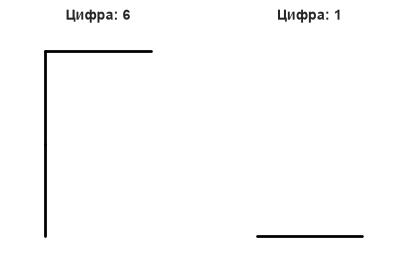

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(5,3))
for (index, row), ax in zip(noise.iterrows(), axes.flat):
    draw_digit(row["B":"H"].values, ax=ax, title=f"Цифра: {row["A"]}")
plt.show()

Оба объекта можно считать аномальными, поскольку их распознанные изображения существенно отличаются от стандартного представления соответствующих цифр. Таким образом, хоть в результате и не получилось содержательных кластеров, из него можно вынести наличие двух выбросов в датасете.

# Вывод
В ходе работы была проведена кластеризация 500 изображений цифр методом DBSCAN с использованием расстояния Хэмминга. Перебор параметров показал, что алгоритм не позволяет получить содержательное разделение данных на кластеры.

При малых значениях $\varepsilon$ формируется большое количество небольших кластеров из одинаковых объектов, при этом значительная часть наблюдений относится к шуму. При увеличении $\varepsilon$ до значения, допускающего отличие на один сегмент, практически все объекты объединяются в один кластер. Это происходит из за особенностей исходных данных и метода. DBSCAN объединяет в один кластер все объекты, связанные цепочкой корневых точек.

Несмотря на плохие результаты кластеризации, DBSCAN смог выделить 2 выброса(сильно искаженные изображения цифр).

Таким образом, на данном датасете DBSCAN оказался малоэффективным для разделения данных на кластеры, однако позволил обнаружить аномальные наблюдения